            Name            Team  Number Position  Age  Height  Weight  \
0  Avery Bradley  Boston Celtics       0       PG   25  06-Feb     180   
1    Jae Crowder  Boston Celtics      99       SF   25  06-Jun     235   
2   John Holland  Boston Celtics      30       SG   27  06-May     205   
3    R.J. Hunter  Boston Celtics      28       SG   22  06-May     185   
4  Jonas Jerebko  Boston Celtics       8       PF   29  06-Oct     231   

             College     Salary  
0              Texas  7730337.0  
1          Marquette  6796117.0  
2  Boston University        NaN  
3      Georgia State  1148640.0  
4                NaN  5000000.0  
Dataset Shape:  (458, 9)
Column Names:  Index(['Name', 'Team', 'Number', 'Position', 'Age', 'Height', 'Weight',
       'College', 'Salary'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 n

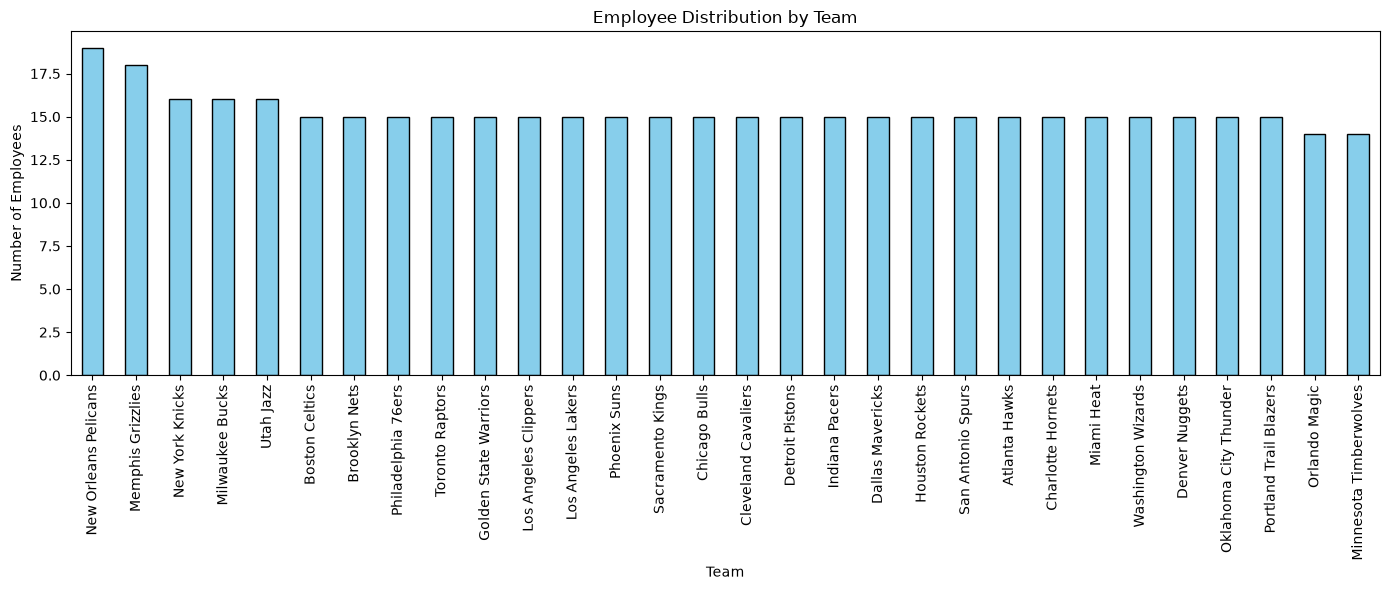

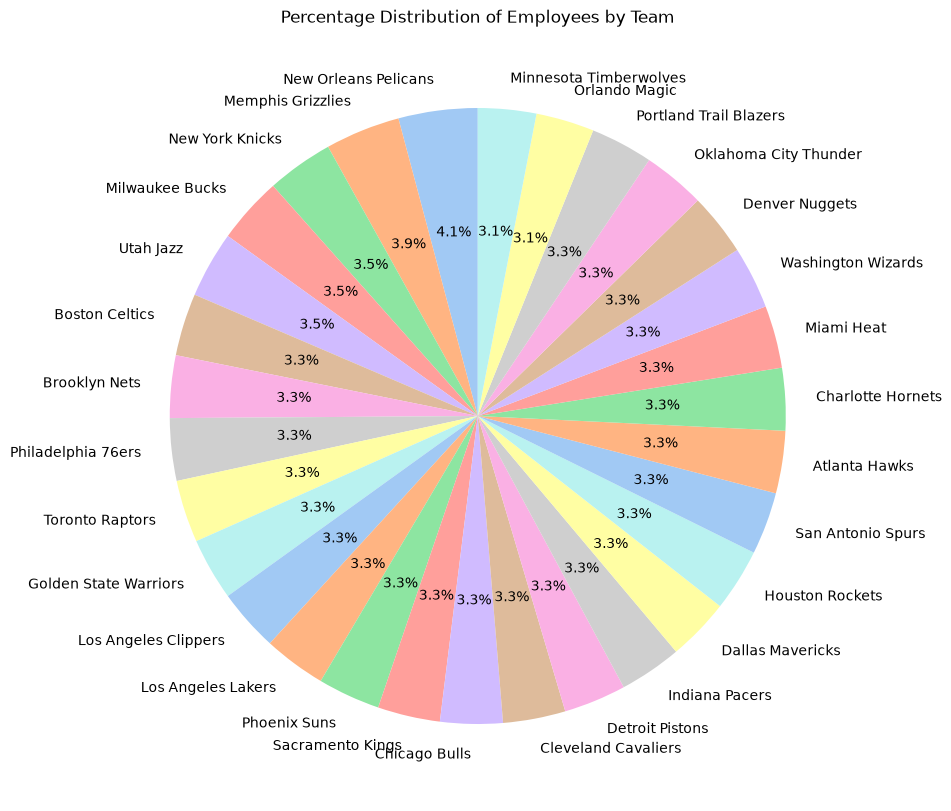

In [15]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load the data
df = pd.read_csv('abc_company_employees.csv')

# Display the first few rows of the data
print(df.head())

# Check dataset shape
print("Dataset Shape: ", df.shape)

# Check column names
print("Column Names: ", df.columns)

# Dataset Information
print("Dataset Information: ", df.info())

# Check for missing values
print(df.isnull().sum())

# --------------------------------
# DATA PREPROCESSING
# --------------------------------

# Replace Height with random values
np.random.seed(42)
df['Height'] = np.random.randint(150,181, size=len(df))

# Display Updated Height Column
print(df[["Name", "Height"]].head(10))

# Verify minimum and maximum height
print("Minimum Height: ", df['Height'].min())
print("Maximum Height: ", df['Height'].max())

# Check dataset shapes
print("Updated Dataset Shape: ", df.shape)

# Save the preprocessed dataset
df.to_csv("preprocessed_abc_company_employees.csv", index=False)
print("Preprocessed dataset saved successfully")

# --------------------------------
# EMPLOYEE DISTRIBUTION BY TEAM
# --------------------------------

# Count of employees in each team
team_counts = df["Team"].value_counts()

print("\nEmployees in each team:")
print(team_counts)

# Calculate percentage of employees in each team
team_percentage = (team_counts / len(df)) * 100

print("\nPercentage Distribution : ")
print(team_percentage.round(2))

# Create a bar chart

plt.figure(figsize=(14,6))
team_counts.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Employee Distribution by Team")
plt.xlabel("Team")
plt.ylabel("Number of Employees")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# Create a pie chart

plt.figure(figsize=(10,10))
team_counts.plot(kind="pie", autopct='%1.1f%%', startangle=90, colors=sns.color_palette("pastel"))

plt.title("Percentage Distribution of Employees by Team")
plt.ylabel("")
plt.show()


Segregate employees based on their positions


Employees in each position:
Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64

Position Percentage: 
Position
SG    22.27
PF    21.83
PG    20.09
SF    18.56
C     17.25
Name: count, dtype: float64


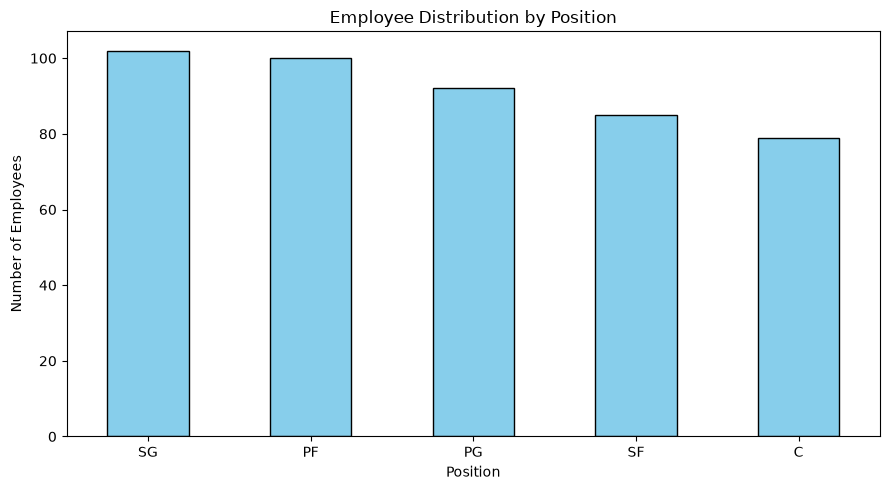

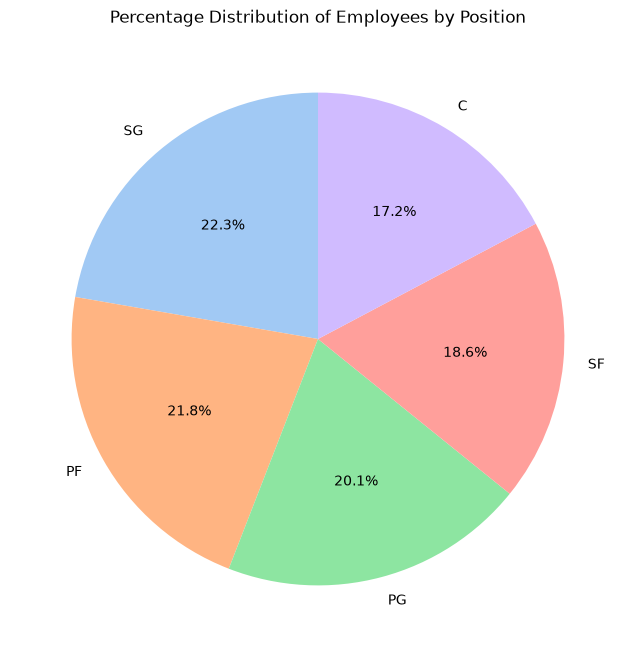

In [16]:
# --------------------------------
# EMPLOYEE DISTRIBUTION BY POSITION
# --------------------------------

position_counts = df["Position"].value_counts()

print("\nEmployees in each position:")
print(position_counts)

# Calculate percentage

position_percentage = (position_counts / len(df)) * 100

print("\nPosition Percentage: ")
print(position_percentage.round(2))

# Visualize using a bar chart

plt.figure(figsize=(9,5))

position_counts.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Employee Distribution by Position")
plt.xlabel("Position")
plt.ylabel("Number of Employees")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Visualize using a pie chart

plt.figure(figsize=(8,8))
position_counts.plot(kind="pie", autopct='%1.1f%%', startangle=90, colors=sns.color_palette("pastel"))

plt.title("Percentage Distribution of Employees by Position")
plt.ylabel("")
plt.show()

Identify the predominant age group among employees


Employees in each age group:
Age Group
18-25    200
26-30    167
31-35     68
36-40     23
Name: count, dtype: int64

Age Group Percentage: 
Age Group
18-25    43.67
26-30    36.46
31-35    14.85
36-40     5.02
Name: count, dtype: float64

Predominant Age Group:  18-25
Number of Employees:  200


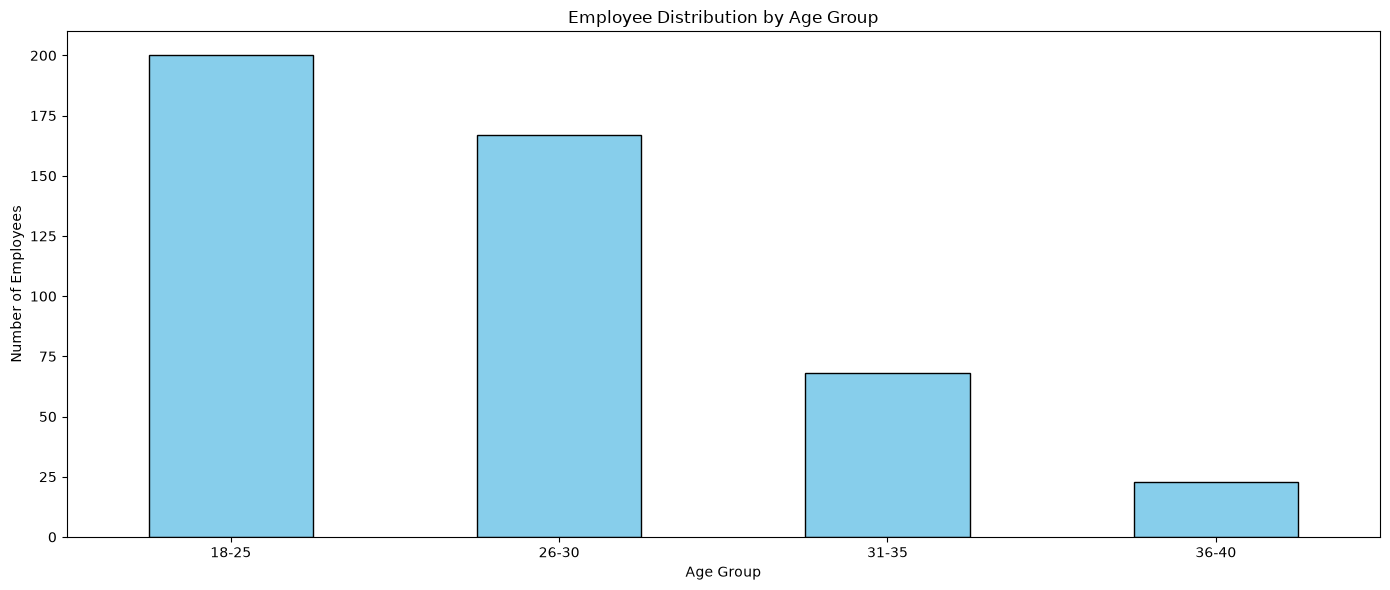

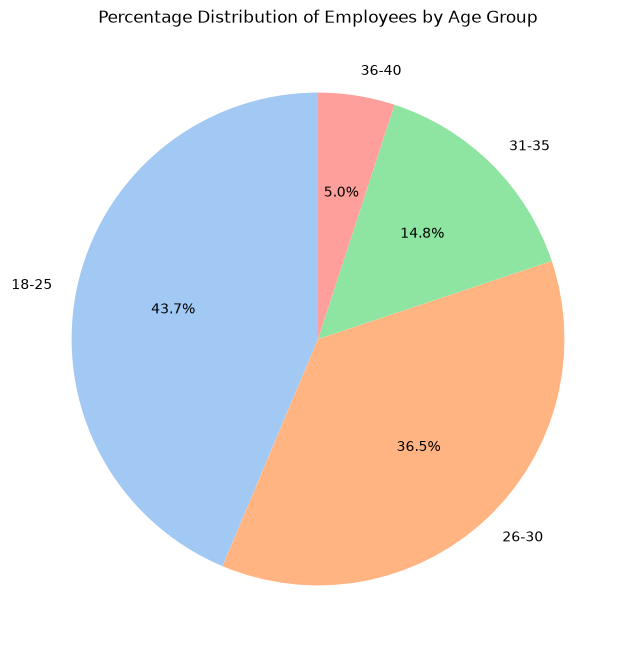

In [17]:
# --------------------------------
# AGE GROUP ANALYSIS
# --------------------------------

# Create age groups

bins = [18,25,30,35,40]
labels = ["18-25", "26-30", "31-35", "36-40"]

df["Age Group"] = pd.cut(df["Age"],bins=bins, labels=labels, include_lowest=True)

# Count of employees in each age group
age_group = df["Age Group"].value_counts().sort_index()

print("\nEmployees in each age group:")
print(age_group)

# Calculate percentage

age_percentage = (age_group / len(df)) * 100

print("\nAge Group Percentage: ")
print(age_percentage.round(2))

# Find the predominant age group
# Find the age group with maximum number of employees

predominant_age_group = age_group.idxmax()
print("\nPredominant Age Group: ", predominant_age_group)
print("Number of Employees: ", age_group.max())

# Visualize the predominant age group in a bar chart

plt.figure(figsize=(14,6))
age_group.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Employee Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Visualize the predominant age group in a pie chart

plt.figure(figsize=(8,8))
age_group.plot(kind="pie", autopct='%1.1f%%', startangle=90, colors=sns.color_palette("pastel"))

plt.title("Percentage Distribution of Employees by Age Group")
plt.ylabel("")
plt.show()


Discover which team and position have the highest salary expenditure


Total Salary Expenditure by Team: 
Team
Cleveland Cavaliers       106988689.0
Los Angeles Clippers       94854640.0
Oklahoma City Thunder      93765298.0
Golden State Warriors      88868997.0
Chicago Bulls              86783378.0
San Antonio Spurs          84442733.0
New Orleans Pelicans       82750774.0
Miami Heat                 82515673.0
Charlotte Hornets          78340920.0
Memphis Grizzlies          76550880.0
Washington Wizards         76328636.0
Houston Rockets            75283021.0
New York Knicks            73303898.0
Atlanta Hawks              72902950.0
Los Angeles Lakers         71770431.0
Sacramento Kings           71683666.0
Dallas Mavericks           71198732.0
Toronto Raptors            71117611.0
Milwaukee Bucks            69603517.0
Detroit Pistons            67168263.0
Indiana Pacers             66751826.0
Utah Jazz                  64007367.0
Phoenix Suns               63445135.0
Orlando Magic              60161470.0
Denver Nuggets             60121930.0
Minnesota

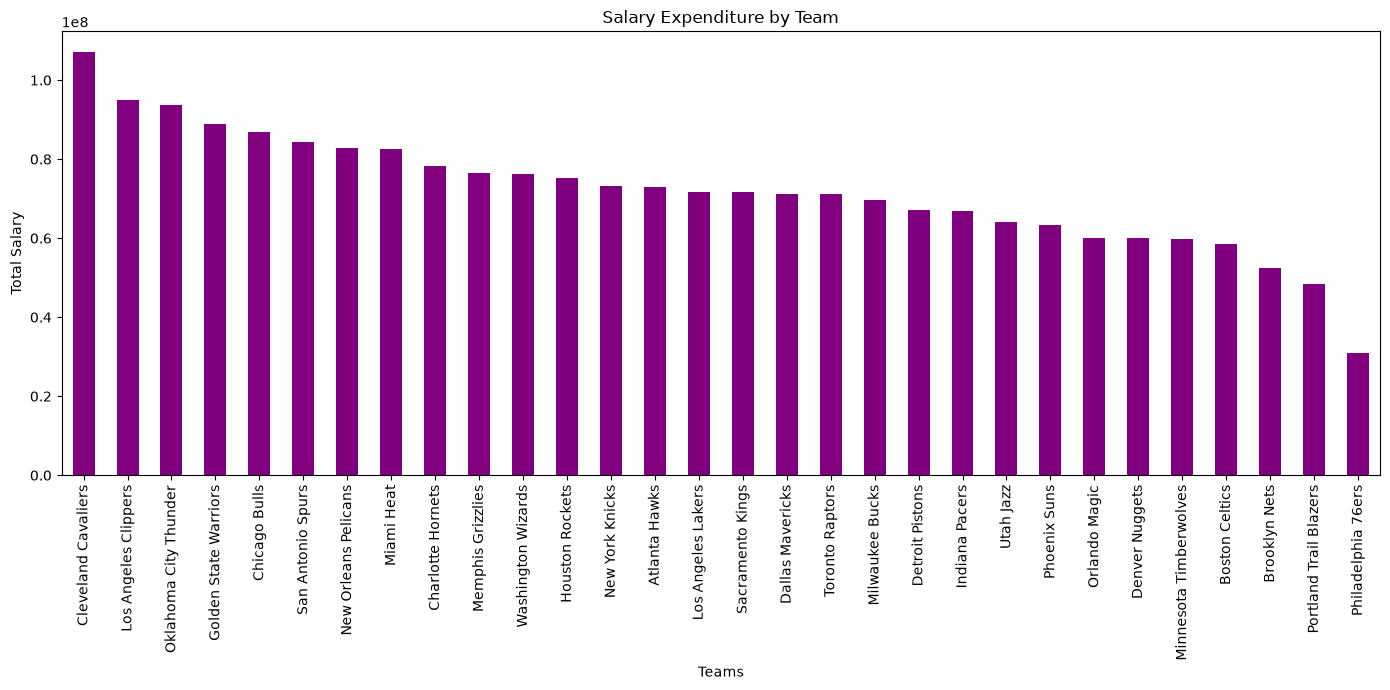

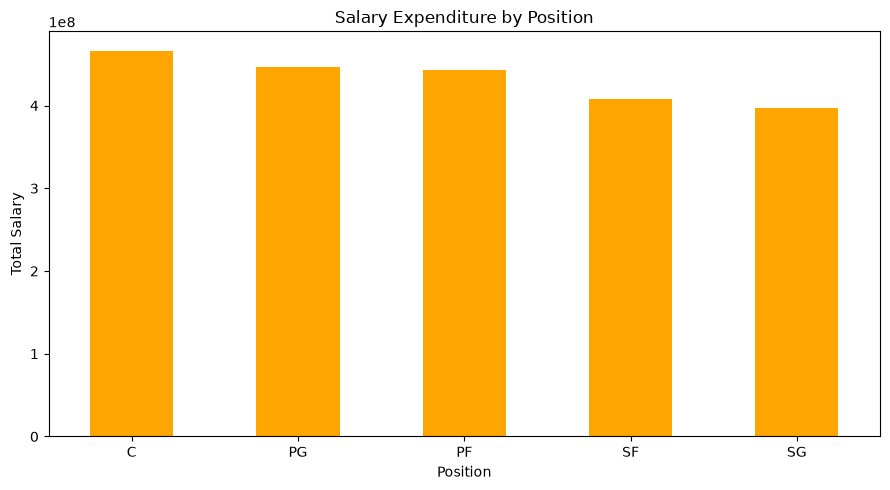

In [18]:
# --------------------------------
# SALARY EXPENDITURE BY TEAM
# --------------------------------

# Calculate total salary for each team

team_salary = df.groupby("Team")["Salary"].sum()
print("\nTotal Salary Expenditure by Team: ")
print(team_salary.sort_values(ascending=False))

# Find team with highest salary expenditure

highest_team = team_salary.idxmax()
highest_team_salary = team_salary.max()

print("\nTeam with Highest Salary Expenditure: ", highest_team)
print("Total Salary Expenditure: ", highest_team_salary)

# Visualize salary expenditure by team

plt.figure(figsize=(14,7))
team_salary.sort_values(ascending=False).plot(kind="bar",color="purple")

plt.title("Salary Expenditure by Team")
plt.xlabel("Teams")
plt.ylabel("Total Salary")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show

# --------------------------------
# SALARY EXPENDITURE BY POSITION
# --------------------------------

# Calculate total salary for each position

position_salary = df.groupby("Position")["Salary"].sum()

print("\nTotal Salary Expenditure by Position:")
print(position_salary.sort_values(ascending=False))

# Find position with highest salary expenditure

highest_position = position_salary.idxmax()

highest_position_salary = position_salary.max()

print("\nPosition with Highest Salary Expenditure:", highest_position)

print("Total Salary Expenditure:", highest_position_salary)

# Visualize salary expenditure by position

plt.figure(figsize=(9, 5))

position_salary.sort_values(ascending=False).plot(
    kind="bar",
    color="orange"
)

plt.title("Salary Expenditure by Position")
plt.xlabel("Position")
plt.ylabel("Total Salary")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Correlation between Age and Salary

In [19]:
# --------------------------------
# CORRELATION BETWEEN AGE AND SALARY
# --------------------------------

# Calculate correlation between Age and Salary

correlation = df["Age"].corr(df["Salary"])

print("\nCorrelation between Age and Salary")
print(correlation)


Correlation between Age and Salary
0.21400941226570977


Understand the correlation value
Correlation values range from -1 to +1.
Correlation	Meaning
+1	Perfect positive correlation
0	No linear correlation
-1	Perfect negative correlation
0.214	Weak positive correlation

Our dataset result: Approximately 0.214.

This means there is a weak positive relationship between employee age and salary.

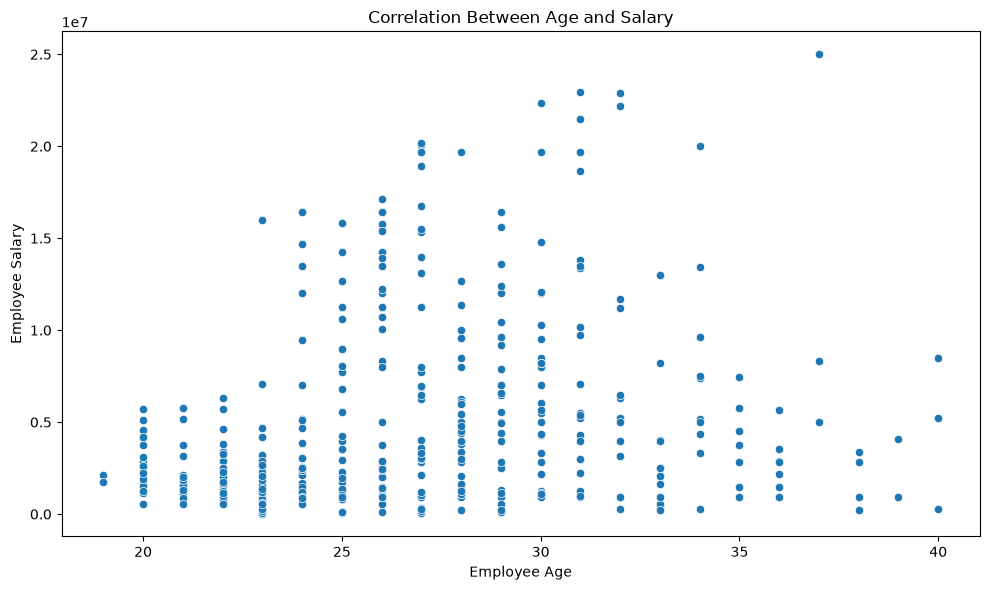

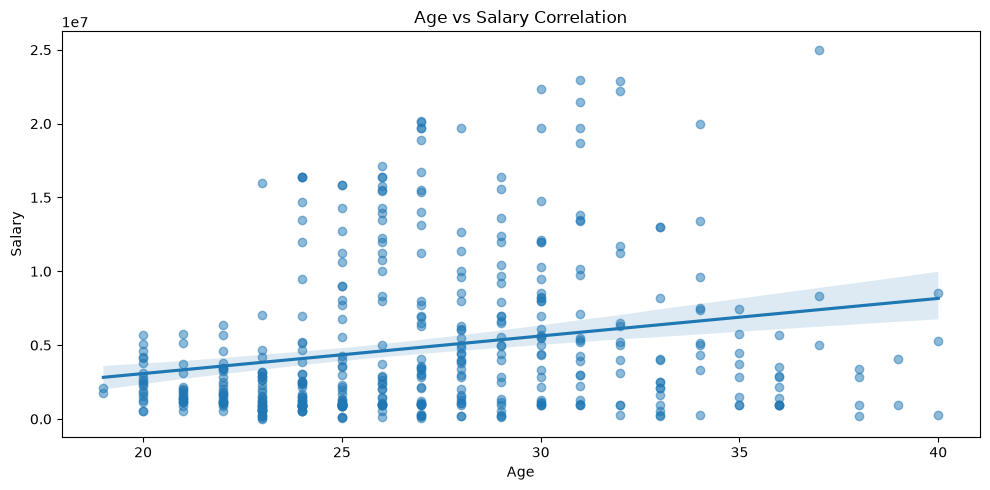

In [20]:
# Create a scatter plot

plt.figure(figsize=(10,6))
sns.scatterplot(x="Age",y="Salary",data=df)

plt.title("Correlation Between Age and Salary")
plt.xlabel("Employee Age")
plt.ylabel("Employee Salary")

plt.tight_layout()
plt.show()

# Add a regression line

plt.figure(figsize=(10,5))
sns.regplot(x="Age",y="Salary",data=df,scatter_kws={"alpha":0.5})

plt.title("Age vs Salary Correlation")
plt.xlabel("Age")
plt.ylabel("Salary")

plt.tight_layout()
plt.show()


Look at the graph:
- Each dot represents one employee.
- X-axis represents employee age.
- Y-axis represents employee salary.
- The trend line represents the general relationship between age and salary.
Our finding: The correlation is approximately 0.214, indicating a weak positive linear relationship. Age alone does not strongly explain salary differences.

In [21]:
correlation_data = df[["Age", "Salary"]].dropna()

correlation = correlation_data["Age"].corr(
    correlation_data["Salary"]
)

print("Correlation:", correlation)

Correlation: 0.21400941226570977


# Data Story: ABC Company Employee Analysis

## Introduction

The purpose of this analysis is to understand the employee structure, age distribution, job positions, and salary expenditure of ABC Company. The dataset contains 458 employee records across 30 teams and 5 different positions.

## Key Findings

### 1. Employee Distribution by Position

The analysis shows that **Shooting Guards (SG)** have the highest number of employees, with 102 employees (22.27%). Centers (C) have the lowest count, with 79 employees (17.25%). This gives us an overview of how employees are distributed across different positions.

### 2. Employee Age Distribution

The most predominant age group is **18–25**, with 200 employees. This represents approximately 43.67% of the workforce. The result indicates that a large portion of the employees in the dataset are relatively young.

### 3. Salary Expenditure by Team

The **Cleveland Cavaliers** have the highest total salary expenditure, amounting to 106,988,689. This suggests that the team has a comparatively high overall salary commitment.

### 4. Salary Expenditure by Position

The **Center (C)** position has the highest total salary expenditure, amounting to 466,377,332. This is an interesting finding because Centers have the lowest employee count among the five positions. It suggests that total salary expenditure depends not only on the number of employees but also on their individual salaries.

### 5. Relationship Between Age and Salary

The correlation between Age and Salary is approximately **0.214**. This indicates a weak positive relationship between employee age and salary. In general, salaries show a slight tendency to increase with age, but the relationship is not strong.

## Conclusion

The analysis provides useful insights into ABC Company's workforce. The 18–25 age group represents the largest share of employees, while Shooting Guards are the most common position. The Cleveland Cavaliers have the highest team salary expenditure, and Centers account for the highest salary expenditure by position.

The correlation analysis shows only a weak positive relationship between age and salary. Overall, this project demonstrates how Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn can be used to clean, analyze, and visualize employee data to support better understanding and decision-making.

*Note: Salary expenditure calculations exclude the 11 records with missing salary values.*